# 01 · Team-Season Offensive & Defensive Breakdown

**Whiteboard project #1 — Year-to-year offense & defense breakdown: team level, run vs. pass, tendencies.**

| Section | What it answers |
|---|---|
| 1. Load the data | How much play-by-play data do we have? |
| 2. Data availability | Which seasons have personnel, coverage, blitz and play-action data? |
| 3. Define the plays | Which plays count, and what is a "neutral situation"? |
| 4. Team-season tables | How good was every offense and defense, every season? |
| 5. League trends | How has the league changed since 2016? |
| 6. Stability | Which team stats actually carry over from one year to the next? |
| 7. Biggest movers | Which teams improved or declined the most? |
| 8. Offense vs. defense map | Where does every team sit on both sides of the ball? |
| 9. Single-team view | One team's full year-to-year profile |

Outputs are saved to `data/processed/` for the next notebooks.

### Key terms

| Term | Meaning | Good is… |
|---|---|---|
| **EPA (Expected Points Added)** | How much a play changed the offense's expected points, based on down, distance, field position and time. | Offense: positive. Defense: negative (less allowed). |
| **Success rate** | Share of plays with positive EPA — a steadier read on consistency than average EPA. | Offense: higher. Defense: lower. |
| **Dropback** | Any called pass play, including sacks and QB scrambles. | — |
| **Designed run** | A called run play (QB scrambles count as dropbacks, not runs). | — |
| **Neutral situation** | 1st or 2nd down, win probability between 20% and 80%, more than 2 minutes left in the half. Removes "trailing late, must pass" effects. | — |
| **Pass rate over expected (PROE)** | Neutral dropback rate minus what the nflverse model expects given the situation. Positive = more pass-heavy than typical. | Style, not quality. |
| **Explosive play** | A dropback gaining 20+ yards or a run gaining 10+ yards. | Offense: higher. Defense: lower. |

## Setup

Imports, data paths, chart style, and two helpers used throughout:

- `show()` displays any table with readable column names, percentages and signed EPA values, plus a title.
- `season_line()` draws a season-by-season line, with the in-progress season shown as a dotted segment and hollow dot.

Paths are relative to the `notebooks/` folder. Run `python -m src.ingest` from the repo root first if `data/raw/` is empty.

In [37]:
from pathlib import Path

import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
PROCESSED.mkdir(parents=True, exist_ok=True)

# ---------- chart style: thin lines, recessive grid, one blue / one orange series ----------
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1f1f1e", "#6b6a64", "#e4e2dc"
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (11, 4),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.labelsize": 10,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlepad": 10,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "lines.linewidth": 2, "lines.markersize": 5,
    "legend.frameon": False, "legend.fontsize": 9,
})


def season_line(ax, seasons, values, last_full, color, label=None, **kw):
    """Solid line through complete seasons; dotted segment + hollow dot for the in-progress season."""
    seasons, values = list(seasons), list(values)
    done = [(s, v) for s, v in zip(seasons, values) if s <= last_full]
    part = [(s, v) for s, v in zip(seasons, values) if s > last_full]
    ax.plot([s for s, _ in done], [v for _, v in done], color=color, marker="o", label=label, **kw)
    if part and done:
        ax.plot([done[-1][0], part[0][0]], [done[-1][1], part[0][1]], color=color, linestyle=":", linewidth=kw.get("linewidth", 2))
        ax.scatter([s for s, _ in part], [v for _, v in part], facecolors="white", edgecolors=color, s=40, zorder=3, linewidths=1.5)


def season_axis(ax, ylabel):
    """Standard x-axis (Season, whole years) and a y-axis label."""
    ax.set_xlabel("Season")
    ax.set_ylabel(ylabel)
    ax.xaxis.set_major_locator(mtick.MaxNLocator(integer=True))


# ---------- readable tables ----------
LABELS = {
    "season": "Season", "team": "Team", "plays": "Plays", "rows": "Rows",
    "epa_per_play": "EPA / Play", "success_rate": "Success Rate",
    "pass_epa": "EPA / Dropback", "rush_epa": "EPA / Designed Run",
    "pass_success": "Dropback Success Rate", "rush_success": "Run Success Rate",
    "pass_rate": "Dropback Rate (All Plays)", "neutral_pass_rate": "Neutral Dropback Rate",
    "proe": "Pass Rate Over Expected", "explosive_rate": "Explosive Play Rate",
    "shotgun_rate": "Shotgun Rate", "no_huddle_rate": "No-Huddle Rate",
    "epa_rank": "EPA Rank (1 = Best)", "pass_epa_rank": "Dropback EPA Rank", "rush_epa_rank": "Run EPA Rank",
    # data-availability fields
    "offense_personnel": "Offensive Personnel", "defense_personnel": "Defensive Personnel",
    "offense_formation": "Offensive Formation", "defenders_in_box": "Defenders in Box",
    "number_of_pass_rushers": "Pass Rushers", "defense_man_zone_type": "Man / Zone",
    "defense_coverage_type": "Coverage Type", "route": "Routes Run",
    "is_play_action": "Play Action", "is_rpo": "RPO", "is_screen_pass": "Screen Pass",
    "is_motion": "Pre-Snap Motion", "n_blitzers": "Blitzers", "n_pass_rushers": "Pass Rushers",
}
DEFENSE_LABELS = {
    "epa_per_play": "EPA Allowed / Play", "success_rate": "Success Rate Allowed",
    "pass_epa": "EPA Allowed / Dropback", "rush_epa": "EPA Allowed / Designed Run",
    "explosive_rate": "Explosive Plays Allowed", "epa_rank": "Defense Rank (1 = Best)",
    "neutral_pass_rate": "Opponent Neutral Dropback Rate",
}
PCT = {"success_rate", "pass_success", "rush_success", "pass_rate", "neutral_pass_rate",
       "explosive_rate", "shotgun_rate", "no_huddle_rate"}


def show(df, title, labels=None, pct=(), signed_pct=("proe",), epa=(), ints=(), fmt=None, note=None):
    """Display a polars table with readable headers and number formats.

    Columns are formatted automatically by name (rates as %, EPA with a +/- sign, ranks and counts as
    whole numbers); pass pct / epa / ints / fmt to override.
    """
    pdf = df.to_pandas() if isinstance(df, pl.DataFrame) else df.copy()
    formats = {}
    for c in pdf.columns:
        if c in PCT or c in pct or c.startswith("has_"):
            formats[c] = "{:.1%}"
        elif c in signed_pct:
            formats[c] = "{:+.1%}"
        elif ("epa" in c and "rank" not in c) or c in epa:
            formats[c] = "{:+.3f}"
        elif c.endswith("rank") or c in ints or c in ("plays", "rows", "dropbacks"):
            formats[c] = "{:,.0f}"
    formats.update(fmt or {})
    names = {**LABELS, **(labels or {})}
    pdf = pdf.rename(columns={c: names.get(c, c) for c in pdf.columns})
    formats = {names.get(c, c): f for c, f in formats.items()}
    caption = f"<b>{title}</b>" + (f"<br><span style='font-weight:normal;color:#6b6a64'>{note}</span>" if note else "")
    styler = (pdf.style.format(formats, na_rep="—")
              .hide(axis="index")
              .set_caption(caption)
              .set_table_styles([
                  {"selector": "caption", "props": "caption-side: top; text-align: left; font-size: 13px; padding-bottom: 6px;"},
                  {"selector": "th", "props": "text-align: center; padding: 4px 10px;"},
                  {"selector": "td", "props": "text-align: center; padding: 3px 10px;"},
              ]))
    display(styler)

## 1. Load the Data

nflverse play-by-play has ~370 columns; we read only the ones this notebook needs, from one parquet file per season, and stack them into one table.

In [38]:
PBP_COLS = [
    "season", "season_type", "week", "game_id", "play_id", "posteam", "defteam",
    "down", "ydstogo", "yardline_100", "qtr", "half_seconds_remaining", "wp",
    "play_type", "pass", "rush", "qb_scramble", "sack", "epa", "success", "yards_gained",
    "air_yards", "shotgun", "no_huddle", "xpass",
]

pbp_files = sorted((RAW / "pbp").glob("pbp_*.parquet"))
pbp = pl.concat([pl.read_parquet(f, columns=PBP_COLS) for f in pbp_files], how="diagonal_relaxed")

LATEST = pbp["season"].max()
latest_week = pbp.filter(pl.col("season") == LATEST)["week"].max()
LAST_FULL = LATEST if latest_week >= 18 else LATEST - 1   # most recent complete season
print(f"Loaded {pbp.height:,} plays from {pbp['season'].min()}–{LATEST}.")
print(f"{LATEST} is in progress (through week {latest_week}); the latest complete season is {LAST_FULL}.")

Loaded 502,992 plays from 2016–2026.
2026 is in progress (through week 7); the latest complete season is 2025.


**Plays per season.** Every snap in the play-by-play, split into regular season and postseason. The in-progress season will look short.

In [39]:
show(
    pbp.group_by("season")
       .agg(plays=pl.len(),
            reg=(pl.col("season_type") == "REG").sum(),
            post=(pl.col("season_type") == "POST").sum(),
            max_week=pl.col("week").max())
       .sort("season"),
    "Plays in the play-by-play data, by season",
    labels={"plays": "All Plays", "reg": "Regular Season Plays", "post": "Postseason Plays", "max_week": "Last Week Played"},
    ints=("reg", "post"),
)

Season,All Plays,Regular Season Plays,Postseason Plays,Last Week Played
2016,"47,651","45,707","1,944",21
2017,"47,245","45,268","1,977",21
2018,"47,109","45,120","1,989",21
2019,"47,260","45,339","1,921",21
2020,"47,705","45,406","2,299",21
2021,"49,922","47,651","2,271",22
2022,"49,434","47,157","2,277",22
2023,"49,665","47,399","2,266",22
2024,"49,492","47,274","2,218",22
2025,"48,771","46,452","2,319",22


## 2. Data Availability by Season

Later projects (personnel, formations, coverages, blitzes) rely on two extra sources whose coverage is uneven:

- **Participation:** personnel groupings, formation, defenders in the box, pass rushers, coverage type, routes. Published 2016–2025.
- **FTN charting:** play action, RPO, screens, motion, number of blitzers. Published 2022–present.

Each cell below is the **share of plays that have a value** for that field — 100% means fully available.

In [40]:
def fill_rates(folder, fields):
    rows = []
    for f in sorted((RAW / folder).glob(f"{folder}_*.parquet")):
        df = pl.read_parquet(f)
        row = {"season": int(f.stem.split("_")[-1]), "rows": df.height}
        for c in fields:
            row[c] = (1 - df[c].null_count() / df.height) if c in df.columns else None
        rows.append(row)
    return pl.DataFrame(rows).sort("season")

PART_FIELDS = ["offense_personnel", "defense_personnel", "offense_formation", "defenders_in_box",
               "number_of_pass_rushers", "defense_man_zone_type", "defense_coverage_type", "route"]
show(fill_rates("participation", PART_FIELDS),
     "Participation data: share of plays with each field filled in",
     labels={"rows": "Plays in File"}, pct=PART_FIELDS,
     note="Coverage fields only apply to pass plays, so ~40–50% of all plays can still mean near-complete dropback coverage (checked below).")

Season,Plays in File,Offensive Personnel,Defensive Personnel,Offensive Formation,Defenders in Box,Pass Rushers,Man / Zone,Coverage Type,Routes Run
2016,"48,434",75.9%,75.9%,72.3%,73.7%,41.9%,0.0%,0.0%,38.7%
2017,"47,998",75.7%,75.7%,72.3%,73.8%,40.8%,0.0%,0.0%,37.4%
2018,"47,875",76.0%,76.0%,72.1%,73.6%,43.2%,38.4%,38.4%,37.4%
2019,"48,034",76.1%,76.1%,73.1%,74.2%,43.3%,38.5%,38.5%,37.0%
2020,"48,513",76.1%,76.1%,73.1%,74.4%,43.5%,39.0%,39.0%,37.5%
2021,"50,714",76.3%,76.3%,73.0%,74.4%,43.3%,38.7%,38.7%,37.3%
2022,"50,150",76.2%,76.2%,73.4%,74.4%,42.7%,37.8%,37.8%,36.2%
2023,"46,168",100.0%,100.0%,80.1%,100.0%,97.2%,100.0%,49.6%,100.0%
2024,"45,919",100.0%,100.0%,79.9%,100.0%,100.0%,100.0%,48.8%,100.0%
2025,"45,184",100.0%,100.0%,79.8%,100.0%,100.0%,100.0%,48.8%,100.0%


**Coverage labels on dropbacks.** Coverage is only charted on pass plays, so this checks the share of *dropbacks* that have a coverage label, by joining participation to the play-by-play.

In [41]:
part = pl.concat(
    [pl.read_parquet(f, columns=["nflverse_game_id", "play_id", "defense_coverage_type", "defense_man_zone_type"])
     for f in sorted((RAW / "participation").glob("participation_*.parquet"))],
    how="diagonal_relaxed",
).rename({"nflverse_game_id": "game_id"})

dropbacks = pbp.filter((pl.col("season_type") == "REG") & (pl.col("pass") == 1))
show(
    dropbacks.join(part, on=["game_id", "play_id"], how="left")
        .group_by("season")
        .agg(dropbacks=pl.len(),
             has_coverage_type=pl.col("defense_coverage_type").is_not_null().mean(),
             has_man_zone=pl.col("defense_man_zone_type").is_not_null().mean())
        .sort("season"),
    "Share of regular-season dropbacks with a coverage label",
    labels={"dropbacks": "Dropbacks", "has_coverage_type": "Has Coverage Type (Cover 1, 3…)", "has_man_zone": "Has Man / Zone"},
    note="0% = not published for that season. Coverage questions should use 2018–2025.",
)

Season,Dropbacks,"Has Coverage Type (Cover 1, 3…)",Has Man / Zone
2016,"21,271",0.0%,0.0%
2017,"20,589",0.0%,0.0%
2018,"20,926",83.7%,83.7%
2019,"21,191",83.6%,83.6%
2020,"21,067",84.9%,84.9%
2021,"22,075",84.3%,84.3%
2022,"21,373",84.1%,84.1%
2023,"21,885",99.6%,100.0%
2024,"21,455",99.8%,100.0%
2025,"20,989",99.9%,100.0%


**FTN charting.** Share of plays with each play-design and pass-rush field.

In [42]:
FTN_FIELDS = ["is_play_action", "is_rpo", "is_screen_pass", "is_motion", "n_blitzers", "n_pass_rushers"]
show(fill_rates("ftn_charting", FTN_FIELDS),
     "FTN charting data: share of plays with each field filled in",
     labels={"rows": "Plays in File"}, pct=FTN_FIELDS,
     note="Available 2022 onward, including the current season.")

Season,Plays in File,Play Action,RPO,Screen Pass,Pre-Snap Motion,Blitzers,Pass Rushers
2022,"41,643",100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
2023,"48,225",100.0%,100.0%,100.0%,100.0%,100.0%,97.1%
2024,"48,031",100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
2025,"47,316",100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
2026,"18,019",100.0%,100.0%,100.0%,100.0%,100.0%,100.0%


## 3. Define the Plays

- **Regular season only** for team-season comparisons (playoff samples are small and uneven).
- A **play** = any dropback or designed run with a valid EPA. Excludes kicks, punts, kneels, spikes and penalty-only plays.
- Flags added for **neutral situations** and **explosive plays** (see Key terms above).

In [43]:
plays = (
    pbp.filter(
        (pl.col("season_type") == "REG")
        & ((pl.col("pass") == 1) | (pl.col("rush") == 1))
        & pl.col("epa").is_not_null()
        & pl.col("posteam").is_not_null()
    )
    .with_columns(
        neutral=((pl.col("down") <= 2) & pl.col("wp").is_between(0.2, 0.8) & (pl.col("half_seconds_remaining") > 120)),
        explosive=(((pl.col("pass") == 1) & (pl.col("yards_gained") >= 20)) | ((pl.col("rush") == 1) & (pl.col("yards_gained") >= 10))),
        pass_over_expected=pl.col("pass") - pl.col("xpass"),
    )
)
print(f"{plays.height:,} regular-season dropbacks and designed runs; {plays['neutral'].mean():.0%} of them are in neutral situations.")

358,146 regular-season dropbacks and designed runs; 43% of them are in neutral situations.


## 4. Team-Season Tables (Offense & Defense)

One row per team per season. **Offense** = what the team's offense produced. **Defense** = what the team's defense *allowed* (and, for tendencies, what opponents did against it). Ranks are within each season, 1 = best: highest EPA for offense, lowest EPA allowed for defense.

The saved parquet files keep short column names (`epa_per_play`, `neutral_pass_rate`, …) for coding; the tables below display readable labels.

In [44]:
def team_season(df: pl.DataFrame, side: str) -> pl.DataFrame:
    team_col = "posteam" if side == "off" else "defteam"
    neutral = pl.col("neutral")
    is_pass, is_rush = pl.col("pass") == 1, pl.col("rush") == 1
    out = (
        df.group_by(["season", team_col])
        .agg(
            plays=pl.len(),
            epa_per_play=pl.col("epa").mean(),
            success_rate=pl.col("success").mean(),
            pass_epa=pl.col("epa").filter(is_pass).mean(),
            rush_epa=pl.col("epa").filter(is_rush).mean(),
            pass_success=pl.col("success").filter(is_pass).mean(),
            rush_success=pl.col("success").filter(is_rush).mean(),
            pass_rate=pl.col("pass").mean(),
            neutral_pass_rate=pl.col("pass").filter(neutral).mean(),
            proe=pl.col("pass_over_expected").filter(neutral).mean(),
            explosive_rate=pl.col("explosive").mean(),
            shotgun_rate=pl.col("shotgun").mean(),
            no_huddle_rate=pl.col("no_huddle").mean(),
        )
        .rename({team_col: "team"})
    )
    better_high = side == "off"
    return out.with_columns(
        epa_rank=pl.col("epa_per_play").rank("min", descending=better_high).over("season").cast(pl.Int32),
        pass_epa_rank=pl.col("pass_epa").rank("min", descending=better_high).over("season").cast(pl.Int32),
        rush_epa_rank=pl.col("rush_epa").rank("min", descending=better_high).over("season").cast(pl.Int32),
    ).sort(["season", "epa_rank"])

offense = team_season(plays, "off")
defense = team_season(plays, "def")

offense.write_parquet(PROCESSED / "team_season_offense.parquet")
defense.write_parquet(PROCESSED / "team_season_defense.parquet")
print(f"Saved {offense.height} team-seasons of offense and {defense.height} of defense to {PROCESSED}/")

Saved 352 team-seasons of offense and 352 of defense to ../data/processed/


**Top 10 offenses** of the latest complete season, ranked by EPA per play.

In [45]:
show(
    offense.filter(pl.col("season") == LAST_FULL).head(10).select(
        "epa_rank", "team", "epa_per_play", "success_rate", "pass_epa", "rush_epa",
        "explosive_rate", "neutral_pass_rate", "proe"),
    f"Top 10 offenses, {LAST_FULL} regular season",
    labels={"epa_rank": "Rank"},
    note="EPA: higher is better. Neutral Dropback Rate and Pass Rate Over Expected describe style, not quality.",
)

Rank,Team,EPA / Play,Success Rate,EPA / Dropback,EPA / Designed Run,Explosive Play Rate,Neutral Dropback Rate,Pass Rate Over Expected
1,NE,+0.157,48.4%,+0.309,-0.084,10.5%,56.6%,+3.9%
2,LA,+0.149,52.2%,+0.235,+0.021,11.4%,58.5%,+6.2%
3,BUF,+0.140,48.6%,+0.219,+0.039,10.9%,51.2%,-1.7%
4,GB,+0.124,48.2%,+0.276,-0.076,10.3%,49.7%,-4.3%
5,DAL,+0.111,47.3%,+0.180,-0.008,8.3%,52.2%,-0.4%
6,SF,+0.090,48.5%,+0.173,-0.033,8.2%,54.5%,+1.4%
7,IND,+0.080,46.5%,+0.097,+0.054,8.0%,55.7%,+2.3%
8,CHI,+0.076,45.7%,+0.119,+0.011,10.1%,53.1%,+0.3%
9,DET,+0.072,45.0%,+0.167,-0.068,10.1%,49.0%,-5.6%
10,NYG,+0.044,43.0%,+0.100,-0.037,8.6%,46.3%,-4.9%


**Top 10 defenses** of the same season, ranked by EPA allowed per play. For defense, **negative EPA allowed is good** — the offense lost expected points against them.

In [46]:
show(
    defense.filter(pl.col("season") == LAST_FULL).head(10).select(
        "epa_rank", "team", "epa_per_play", "success_rate", "pass_epa", "rush_epa", "explosive_rate"),
    f"Top 10 defenses, {LAST_FULL} regular season",
    labels={**DEFENSE_LABELS, "epa_rank": "Rank"},
    note="All columns are what the defense allowed: lower (more negative) is better.",
)

Rank,Team,EPA Allowed / Play,Success Rate Allowed,EPA Allowed / Dropback,EPA Allowed / Designed Run,Explosive Plays Allowed
1,SEA,-0.111,40.1%,-0.061,-0.207,5.7%
2,HOU,-0.109,39.5%,-0.097,-0.129,6.9%
3,MIN,-0.085,41.7%,-0.086,-0.085,7.4%
4,CLE,-0.085,40.8%,-0.091,-0.078,8.1%
5,JAX,-0.080,42.3%,-0.067,-0.108,6.7%
6,LAC,-0.076,41.6%,-0.051,-0.117,7.8%
7,LA,-0.067,41.9%,-0.049,-0.098,7.8%
8,DEN,-0.060,37.7%,-0.037,-0.105,5.7%
9,PHI,-0.050,42.6%,-0.016,-0.101,8.3%
10,NO,-0.048,42.0%,+0.018,-0.131,8.1%


## 5. League Trends Since 2016

How the whole league has shifted season to season. Dropback and designed-run EPA share one axis because they're the same unit. The in-progress season is drawn with a dotted line and hollow dot.

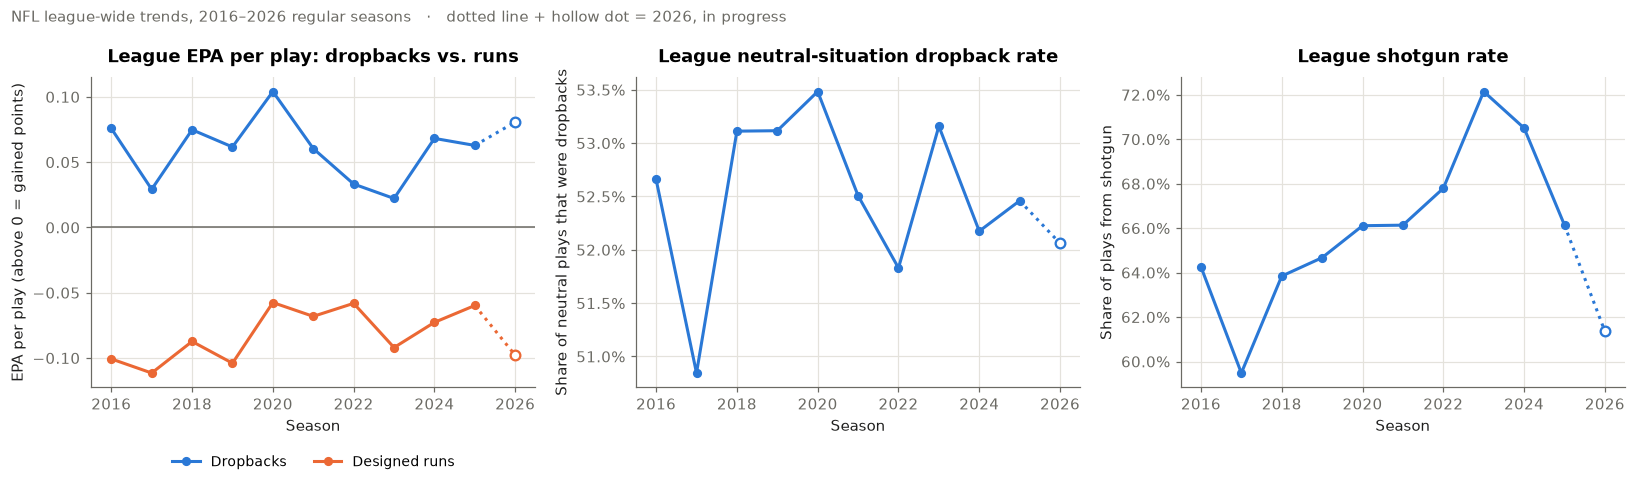

Season,EPA / Play,EPA / Dropback,EPA / Designed Run,Success Rate,Neutral Dropback Rate,Shotgun Rate
2016,+0.010,+0.076,-0.101,43.6%,52.7%,64.3%
2017,-0.025,+0.029,-0.111,41.9%,50.8%,59.5%
2018,+0.014,+0.075,-0.087,44.4%,53.1%,63.8%
2019,-0.000,+0.062,-0.104,43.3%,53.1%,64.7%
2020,+0.043,+0.104,-0.058,45.8%,53.5%,66.1%
2021,+0.012,+0.060,-0.068,44.5%,52.5%,66.1%
2022,-0.003,+0.033,-0.058,44.0%,51.8%,67.8%
2023,-0.021,+0.022,-0.092,43.0%,53.2%,72.1%
2024,+0.013,+0.068,-0.073,44.1%,52.2%,70.5%
2025,+0.015,+0.063,-0.060,44.3%,52.5%,66.1%


In [47]:
league = (
    plays.group_by("season")
    .agg(
        epa_per_play=pl.col("epa").mean(),
        pass_epa=pl.col("epa").filter(pl.col("pass") == 1).mean(),
        rush_epa=pl.col("epa").filter(pl.col("rush") == 1).mean(),
        success_rate=pl.col("success").mean(),
        neutral_pass_rate=pl.col("pass").filter(pl.col("neutral")).mean(),
        shotgun_rate=pl.col("shotgun").mean(),
    )
    .sort("season")
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))

ax = axes[0]
season_line(ax, league["season"], league["pass_epa"], LAST_FULL, BLUE, "Dropbacks")
season_line(ax, league["season"], league["rush_epa"], LAST_FULL, ORANGE, "Designed runs")
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_title("League EPA per play: dropbacks vs. runs")
season_axis(ax, "EPA per play (above 0 = gained points)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)

ax = axes[1]
season_line(ax, league["season"], league["neutral_pass_rate"], LAST_FULL, BLUE)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1))
ax.set_title("League neutral-situation dropback rate")
season_axis(ax, "Share of neutral plays that were dropbacks")

ax = axes[2]
season_line(ax, league["season"], league["shotgun_rate"], LAST_FULL, BLUE)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1))
ax.set_title("League shotgun rate")
season_axis(ax, "Share of plays from shotgun")

fig.suptitle(f"NFL league-wide trends, {league['season'].min()}–{LATEST} regular seasons   ·   dotted line + hollow dot = {LATEST}, in progress",
             x=0.01, ha="left", color=MUTED, fontsize=10)
fig.tight_layout()
plt.show()

show(league, "League averages by season (regular season)",
     note=f"{LATEST} is in progress.")

## 6. Which Team Stats Carry Over Year to Year?

Before reading anything into a team's change from one season to the next, it helps to know which stats are a real **team trait** and which are mostly **noise**. For each stat, we correlate every team's value in one season with its value the next season (all complete seasons).

**How to read it:** 1.00 = the stat repeats perfectly, 0.00 = last year tells you nothing about this year. Roughly: above 0.5 sticky, 0.3–0.5 moderate, below 0.3 mostly noise.

In [48]:
METRICS = ["epa_per_play", "success_rate", "pass_epa", "rush_epa", "neutral_pass_rate",
           "proe", "explosive_rate", "shotgun_rate", "no_huddle_rate"]

def year_over_year(table: pl.DataFrame, side: str) -> pl.DataFrame:
    t = table.filter(pl.col("season") <= LAST_FULL)
    nxt = t.select(["team", (pl.col("season") - 1).alias("season"), *[pl.col(m).alias(f"{m}_next") for m in METRICS]])
    pairs = t.join(nxt, on=["team", "season"], how="inner")
    return pl.DataFrame({
        "metric": METRICS,
        f"{side}_yoy_r": [pairs.select(pl.corr(m, f"{m}_next")).item() for m in METRICS],
    })

stability = (year_over_year(offense, "off").join(year_over_year(defense, "def"), on="metric")
             .sort("off_yoy_r", descending=True)
             .with_columns(pl.col("metric").replace(LABELS)))
show(stability,
     f"Year-to-year correlation of team stats, {offense['season'].min()}–{LAST_FULL}",
     labels={"metric": "Stat", "off_yoy_r": "Offense: Year-to-Year Correlation", "off": "", "def_yoy_r": "Defense: Year-to-Year Correlation"},
     fmt={"off_yoy_r": "{:.2f}", "def_yoy_r": "{:.2f}"},
     note="Defensive stats are those allowed / faced by the defense.")

Stat,Offense: Year-to-Year Correlation,Defense: Year-to-Year Correlation
Shotgun Rate,0.67,0.44
No-Huddle Rate,0.56,0.26
Neutral Dropback Rate,0.42,0.17
Pass Rate Over Expected,0.40,0.19
EPA / Dropback,0.39,0.24
EPA / Play,0.39,0.26
Success Rate,0.38,0.25
EPA / Designed Run,0.34,0.24
Explosive Play Rate,0.30,0.30


## 7. Biggest Year-to-Year Movers

Change in EPA per play from the previous season to the latest complete season.

- **Offense:** a positive change is an improvement.
- **Defense:** a *negative* change is an improvement (less EPA allowed). "Ranks Gained" is positive for improvement on both sides.

In [49]:
def movers(table: pl.DataFrame, season: int) -> pl.DataFrame:
    cur = table.filter(pl.col("season") == season).select("team", "epa_per_play", "epa_rank")
    prev = table.filter(pl.col("season") == season - 1).select(
        "team", pl.col("epa_per_play").alias("prev_epa"), pl.col("epa_rank").alias("prev_rank"))
    return (cur.join(prev, on="team")
               .with_columns(change=pl.col("epa_per_play") - pl.col("prev_epa"),
                             rank_change=pl.col("prev_rank") - pl.col("epa_rank"))
               .select("team", "prev_epa", "prev_rank", "epa_per_play", "epa_rank", "change", "rank_change"))

PREV = LAST_FULL - 1
mover_fmt = {"prev_rank": "{:.0f}", "epa_rank": "{:.0f}", "rank_change": "{:+.0f}", "change": "{:+.3f}"}
off_labels = {"prev_epa": f"{PREV} EPA / Play", "prev_rank": f"{PREV} Rank", "epa_per_play": f"{LAST_FULL} EPA / Play",
              "epa_rank": f"{LAST_FULL} Rank", "change": "Change in EPA / Play", "rank_change": "Ranks Gained"}
def_labels = {"prev_epa": f"{PREV} EPA Allowed / Play", "prev_rank": f"{PREV} Rank", "epa_per_play": f"{LAST_FULL} EPA Allowed / Play",
              "epa_rank": f"{LAST_FULL} Rank", "change": "Change in EPA Allowed", "rank_change": "Ranks Gained"}

off_moves = movers(offense, LAST_FULL)
def_moves = movers(defense, LAST_FULL)

show(off_moves.sort("change", descending=True).head(5), f"Offense: 5 most improved, {PREV} → {LAST_FULL}", labels=off_labels, fmt=mover_fmt)
show(off_moves.sort("change").head(5), f"Offense: 5 biggest declines, {PREV} → {LAST_FULL}", labels=off_labels, fmt=mover_fmt)
show(def_moves.sort("change").head(5), f"Defense: 5 most improved, {PREV} → {LAST_FULL}", labels=def_labels, fmt=mover_fmt,
     note="Negative change = allowed less EPA = better.")
show(def_moves.sort("change", descending=True).head(5), f"Defense: 5 biggest declines, {PREV} → {LAST_FULL}", labels=def_labels, fmt=mover_fmt)

Team,2024 EPA / Play,2024 Rank,2025 EPA / Play,2025 Rank,Change in EPA / Play,Ranks Gained
NE,-0.079,27,+0.157,1,+0.236,+26
DAL,-0.090,28,+0.111,5,+0.201,+23
CHI,-0.075,26,+0.076,8,+0.150,+18
NYG,-0.092,29,+0.044,10,+0.136,+19
IND,-0.047,24,+0.080,7,+0.128,+17


Team,2024 EPA / Play,2024 Rank,2025 EPA / Play,2025 Rank,Change in EPA / Play,Ranks Gained
BAL,+0.197,1,+0.037,15,-0.160,-14
MIN,+0.037,14,-0.094,28,-0.131,-14
TB,+0.132,5,+0.002,20,-0.130,-15
NYJ,+0.001,17,-0.124,29,-0.125,-12
WAS,+0.139,4,+0.034,16,-0.106,-12


Team,2024 EPA Allowed / Play,2024 Rank,2025 EPA Allowed / Play,2025 Rank,Change in EPA Allowed,Ranks Gained
JAX,+0.127,31,-0.080,5,-0.207,+26
NE,+0.083,30,-0.041,11,-0.124,+19
LA,+0.050,23,-0.067,7,-0.117,+16
CLE,+0.017,18,-0.085,4,-0.102,+14
CAR,+0.154,32,+0.060,23,-0.094,+9


Team,2024 EPA Allowed / Play,2024 Rank,2025 EPA Allowed / Play,2025 Rank,Change in EPA Allowed,Ranks Gained
GB,-0.068,4,+0.043,22,+0.110,-18
WAS,+0.043,20,+0.152,31,+0.109,-11
MIA,-0.021,8,+0.086,25,+0.107,-17
NYJ,+0.046,22,+0.147,30,+0.101,-8
DAL,+0.068,28,+0.162,32,+0.095,-4


## 8. Offense vs. Defense Map

Every team in the latest complete season. **Up and to the right is good on both sides.** The defensive axis is flipped so that allowing *less* EPA plots higher. Dashed lines are league averages, splitting the chart into four groups.

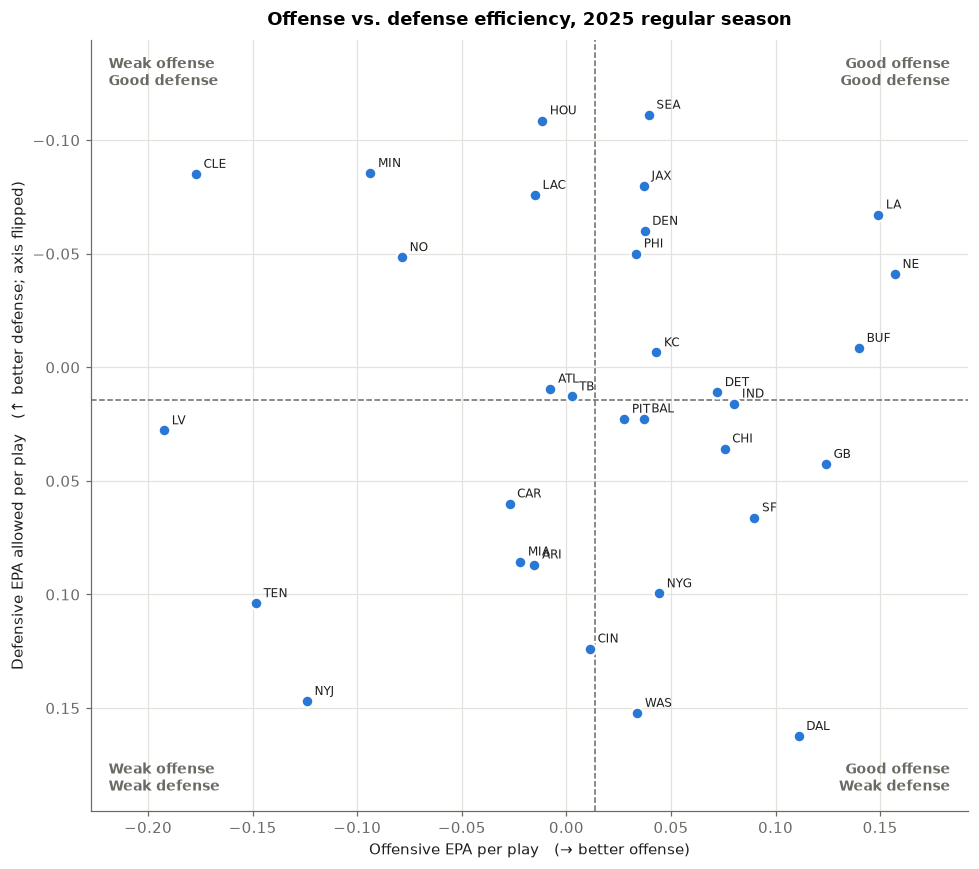

In [50]:
o = offense.filter(pl.col("season") == LAST_FULL).select("team", pl.col("epa_per_play").alias("off_epa"))
d = defense.filter(pl.col("season") == LAST_FULL).select("team", pl.col("epa_per_play").alias("def_epa"))
od = o.join(d, on="team")

fig, ax = plt.subplots(figsize=(9, 8))
ax.scatter(od["off_epa"], od["def_epa"], s=60, color=BLUE, edgecolors="white", linewidths=1.5, zorder=3)
for team, x, y in od.iter_rows():
    ax.annotate(team, (x, y), xytext=(5, 4), textcoords="offset points", fontsize=8, color=INK)
ax.axvline(od["off_epa"].mean(), color=MUTED, linestyle="--", linewidth=1)
ax.axhline(od["def_epa"].mean(), color=MUTED, linestyle="--", linewidth=1)
ax.margins(x=0.1, y=0.12)   # room for the corner labels
ax.invert_yaxis()

# quadrant labels (axes coordinates: 0,0 = bottom-left)
q = dict(transform=ax.transAxes, fontsize=9, color=MUTED, fontweight="bold")
ax.text(0.98, 0.98, "Good offense\nGood defense", ha="right", va="top", **q)
ax.text(0.02, 0.98, "Weak offense\nGood defense", ha="left", va="top", **q)
ax.text(0.98, 0.02, "Good offense\nWeak defense", ha="right", va="bottom", **q)
ax.text(0.02, 0.02, "Weak offense\nWeak defense", ha="left", va="bottom", **q)

ax.set_xlabel("Offensive EPA per play   (→ better offense)")
ax.set_ylabel("Defensive EPA allowed per play   (↑ better defense; axis flipped)")
ax.set_title(f"Offense vs. defense efficiency, {LAST_FULL} regular season")
plt.tight_layout()
plt.show()

## 9. Single-Team View

Change `TEAM` to any team abbreviation (e.g. `"SF"`, `"KC"`, `"DET"`) to see its year-to-year profile next to the league average.

**On every chart, higher is better.** Offensive EPA is good when positive. Defensive EPA is what the defense *allowed*, so negative is good — that axis is flipped so a strong defense plots high. In the table, a negative "EPA Allowed / Play" and a low "Defense Rank" mean a good defense.

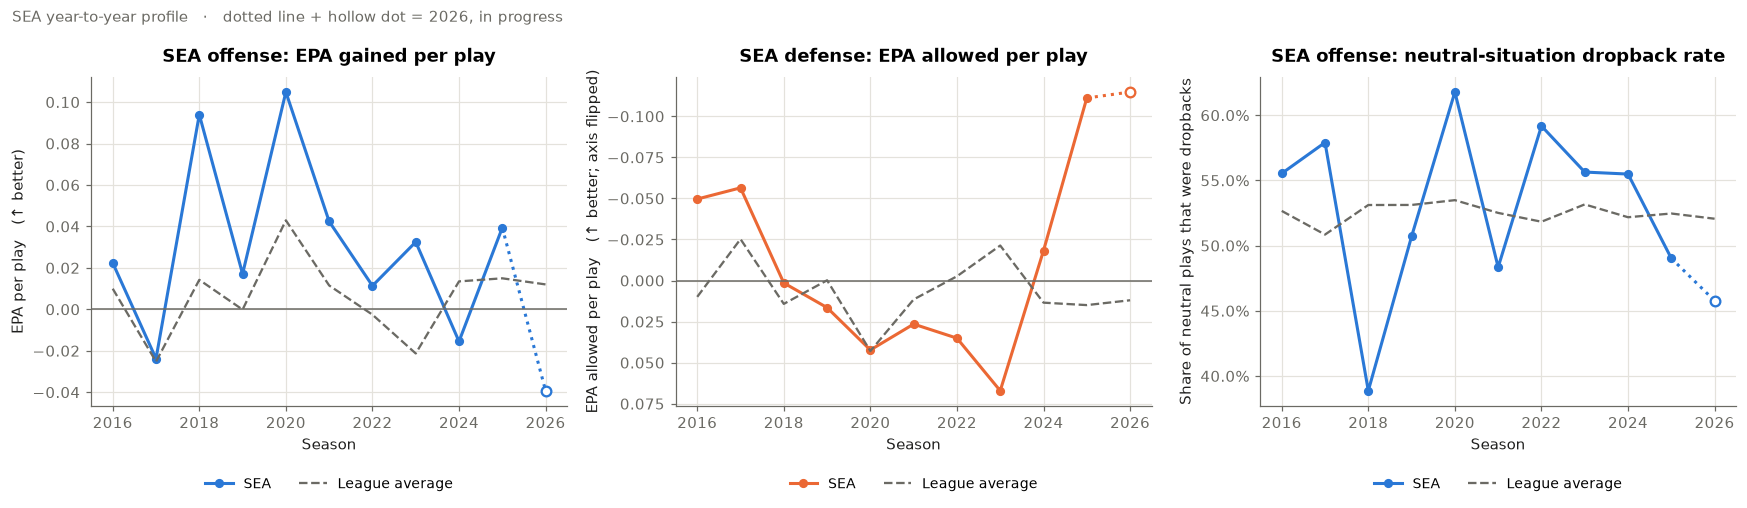

Season,Offense Rank,Offense EPA / Play,Offense EPA / Dropback,Offense EPA / Run,Neutral Dropback Rate,Pass Rate Over Expected,Shotgun Rate,Defense Rank,Defense EPA Allowed / Play
2016,14,+0.022,+0.102,-0.126,55.5%,+2.6%,69.4%,6,-0.050
2017,15,-0.024,+0.058,-0.192,57.9%,+3.9%,62.4%,10,-0.056
2018,6,+0.094,+0.210,-0.027,38.9%,-14.6%,68.8%,13,+0.001
2019,13,+0.017,+0.119,-0.136,50.7%,-2.3%,71.5%,19,+0.016
2020,7,+0.105,+0.164,-0.014,61.8%,+9.4%,70.4%,18,+0.042
2021,14,+0.042,+0.053,+0.026,48.3%,-4.1%,64.3%,20,+0.027
2022,14,+0.011,+0.057,-0.071,59.2%,+5.9%,68.8%,27,+0.035
2023,10,+0.032,+0.095,-0.087,55.6%,+2.1%,72.7%,30,+0.067
2024,18,-0.016,+0.040,-0.126,55.5%,+1.5%,77.7%,10,-0.018
2025,12,+0.039,+0.142,-0.076,49.0%,-4.1%,46.3%,1,-0.111


In [51]:
TEAM = "SEA"

t_off = offense.filter(pl.col("team") == TEAM).sort("season")
t_def = defense.filter(pl.col("team") == TEAM).sort("season")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

ax = axes[0]
season_line(ax, t_off["season"], t_off["epa_per_play"], LAST_FULL, BLUE, TEAM)
ax.plot(league["season"], league["epa_per_play"], color=MUTED, linestyle="--", linewidth=1.5, label="League average")
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_title(f"{TEAM} offense: EPA gained per play")
season_axis(ax, "EPA per play   (↑ better)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)

ax = axes[1]
season_line(ax, t_def["season"], t_def["epa_per_play"], LAST_FULL, ORANGE, TEAM)
ax.plot(league["season"], league["epa_per_play"], color=MUTED, linestyle="--", linewidth=1.5, label="League average")
ax.axhline(0, color=MUTED, linewidth=1)
ax.invert_yaxis()
ax.set_title(f"{TEAM} defense: EPA allowed per play")
season_axis(ax, "EPA allowed per play   (↑ better; axis flipped)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)

ax = axes[2]
season_line(ax, t_off["season"], t_off["neutral_pass_rate"], LAST_FULL, BLUE, TEAM)
ax.plot(league["season"], league["neutral_pass_rate"], color=MUTED, linestyle="--", linewidth=1.5, label="League average")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1))
ax.set_title(f"{TEAM} offense: neutral-situation dropback rate")
season_axis(ax, "Share of neutral plays that were dropbacks")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)

fig.suptitle(f"{TEAM} year-to-year profile   ·   dotted line + hollow dot = {LATEST}, in progress",
             x=0.01, ha="left", color=MUTED, fontsize=10)
fig.tight_layout()
plt.show()

team_table = t_off.select("season", "epa_rank", "epa_per_play", "pass_epa", "rush_epa", "neutral_pass_rate", "proe", "shotgun_rate").join(
    t_def.select("season", pl.col("epa_rank").alias("def_rank"), pl.col("epa_per_play").alias("def_epa")), on="season")
show(team_table, f"{TEAM} by season: offense and defense",
     labels={"epa_rank": "Offense Rank", "epa_per_play": "Offense EPA / Play", "pass_epa": "Offense EPA / Dropback",
             "rush_epa": "Offense EPA / Run", "def_rank": "Defense Rank", "def_epa": "Defense EPA Allowed / Play"},
     note=f"Ranks: 1 = best of 32. Defense EPA allowed: negative = good. {LATEST} is in progress.")

## Next

- **02 · Personnel & concepts:** join participation and FTN charting to break offense down by personnel grouping, formation, play action / RPO / screens, and defense by personnel, box count, blitz rate and coverage (whiteboard project #2).
- That sets up the matchup questions: which concepts beat which coverages and blitzes, and the reverse.